# 합의 신규 용암의 **잔열 상태** 분류 v2 — Grindavík·Sundhnúkur (실제 위성데이터)

`lava_state_real_data.ipynb`(v1) 정리판. **v1에서 바뀐 것과 이유:**

| # | 변경 | 이유 |
|---|------|------|
| 1 | 라벨 명칭 **"흐르는/활동" → "잔열(아직 따뜻함) vs 냉각(배경 수준)"** | 2025-09 촬영 시점엔 분화 비활성. 발표 PDF가 이미 ">100°C 화소 0개, 전부 냉각"이라 결론 — "흐르는 용암 20km²"는 발표와 자기모순. ΔLST′ 임계가 실제로 측정하는 건 **잔열**임 |
| 2 | 특징에서 **LST_25 제거** (광학+SAR만 사용) | 라벨이 ΔLST′ 임계로 만들어졌는데 LST_25는 ΔLST′와 거의 같은 정보 → **라벨 누수**. v1 특징 중요도 1위가 LST_25였던 게 그 증거. v1의 94% 정확도는 상당 부분 "LST 임계 복원" (§4-2에서 비교 재현) |
| 3 | **공간 블록 교차검증** 추가 (500m 블록 GroupKFold) | 픽셀 랜덤 분할은 이웃 픽셀(거의 동일값)이 train/test 양쪽에 들어가 지표가 부풀음. 발표 U-Net도 좌/우 공간 분할 사용 — 같은 철학. v1의 "공간블록분할" 셀은 주석만 있고 코드는 베이스라인 복붙이었음 |
| 4 | 합의 용암을 **발표 공식 산출물(20.97 km²)과 일치** | v1은 자체 임계로 28.5 km² → 발표 헤드라인(≈21 km²)과 불일치. 캐시 모드에선 `consensus_lava.tif`를 그대로 사용 |
| 5 | **클래스 불균형 보정 + balanced accuracy 보고** | 공식 격자에서 잔열:냉각 ≈ 86:14 → "전부 잔열" 더미도 정확도 86%. 정확도 단독 보고는 과장 |
| 6 | 한글 폰트 자동 설정 (Windows/macOS/Linux) | v1 그림 제목·범례의 한글이 □□로 깨짐 |
| 7 | TensorFlow → **PyTorch** | 팀 워크스페이스에서 실행·검증 가능 (구조는 동일: 64-32-16 MLP) |
| 8 | 중복 셀 정리, `df.dNDVI*0` 같은 무의미 항 제거, 민감도 분석을 연속 스윕으로 | 가독성·정보량 |

**연구 질문(재정의):** 합의 신규 용암(21 km²) 안에서, **열 정보 없이 광학+SAR 신호만으로 "아직 따뜻한 용암(잔열)"을 구분할 수 있는가?**
가능하다면 → 야간/열영상 부재 시에도 잔열(=비교적 최근에 두껍게 쌓인) 구역을 추정할 수 있다는 의미.

> 발표 위험도 분석(fig15, SWIR 기반 구 17.2 / 최신 3.7 km²)은 "**언제** 생겼나", 이 노트북은 "**얼마나 식었나**"를 묻는다 — 서로 보완 관계.

In [1]:
# 최초 1회만: 패키지 설치 (필요시 주석 해제)
# %pip install numpy pandas rasterio scikit-learn torch matplotlib
# (다운로드 모드 추가) %pip install xarray rioxarray pystac-client planetary-computer odc-stac

In [2]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
import matplotlib.font_manager as fm
warnings.filterwarnings("ignore")

# ---- 한글 폰트 자동 설정 (v1: 그림 한글 깨짐 수정) ----
for _p in (r"C:/Windows/Fonts/malgun.ttf",                       # Windows
           "/usr/share/fonts/truetype/nanum/NanumGothicBold.ttf",  # Linux(워크스페이스)
           "/System/Library/Fonts/Supplemental/AppleGothic.ttf"):  # macOS
    if os.path.exists(_p):
        fm.fontManager.addfont(_p)
        mpl.rcParams["font.family"] = fm.FontProperties(fname=_p).get_name()
        break
mpl.rcParams["axes.unicode_minus"] = False

CRS, RES, PX = "EPSG:32627", 10.0, 1e-4          # 1픽셀(10m)=1e-4 km²
BBOX = [-22.55, 63.815, -22.28, 63.945]          # W,S,E,N (발표와 동일 AOI)
HOT_THR, COLD_THR = 3.5, 1.5                     # ΔLST′(°C): ≥3.5 잔열 / <1.5 냉각 / 사이 모호(제외)

# 캐시 모드: 발표 파이프라인 산출 래스터(project_iceland/data) 재사용 → 다운로드 불필요·발표 수치와 동일 격자
CACHE = "/workspace/원격탐사/project_iceland/data"
USE_CACHE = os.path.isdir(CACHE)
print("실행 모드:", "캐시(발표 산출물 재사용)" if USE_CACHE else "다운로드(Planetary Computer, 회당 수 분)")

실행 모드: 캐시(발표 산출물 재사용)


## 1) 데이터 로드

- **캐시 모드**(팀 워크스페이스): 발표 파이프라인이 저장한 GeoTIFF를 그대로 읽음 → 발표 수치와 **정확히 같은 격자·같은 합의 마스크**.
- **다운로드 모드**(개인 PC): v1과 같이 Planetary Computer STAC에서 S2/S1 RTC/Landsat을 직접 수집. 격자가 달라 수치가 ±10% 변동 가능.

필요 레이어: NDVI(2023)·ΔNDVI·ΔNBR(광학), ΔVV·ΔVH(SAR), ΔLST′(열, 라벨용), LST 2025(누수 데모용), 육지 마스크, 합의 용암 마스크, 트루컬러 배경.

In [3]:
import rasterio

if USE_CACHE:
    def rd(name, band=1):
        with rasterio.open(f"{CACHE}/{name}") as r:
            return r.read(band).astype("float32")
    NDVI23, NDVI25 = rd("ndvi_2023.tif"), rd("ndvi_2025.tif")
    dNDVI = rd("d_ndvi.tif")
    dNBR  = rd("nbr_2025.tif") - rd("nbr_2023.tif")
    _s1a = rasterio.open(f"{CACHE}/s1_2023.tif").read()   # [VV,VH] dB
    _s1b = rasterio.open(f"{CACHE}/s1_2025.tif").read()
    dVV, dVH = _s1b[0] - _s1a[0], _s1b[1] - _s1a[1]
    LST25, dLSTa = rd("lst_2025.tif"), rd("lst_anom.tif")  # ΔLST′ = (LST25-LST23) - 배경평균
    LAND = rd("land.tif") > 0.5
    CONSENSUS = rd("consensus_lava.tif") == 1              # 발표 공식: 광학 ∧ (SAR ∨ 열) = 20.97 km²
    with rasterio.open(f"{CACHE}/s2_2025.tif") as r:
        S2_25 = r.read(); TRANSFORM, B = r.transform, r.bounds
    H, W = dNDVI.shape
    EXT = [B.left, B.right, B.bottom, B.top]
    print(f"격자 {W}x{H} @10m | 육지 {LAND.sum()*PX:.1f} km² | 합의 신규용암 {CONSENSUS.sum()*PX:.2f} km² (발표: 20.97)")
    print(f"육지 NDVI {np.nanmean(NDVI23[LAND]):.3f} → {np.nanmean(NDVI25[LAND]):.3f}  (발표: 0.40 → 0.37)  ← v1은 바다 포함 평균(0.20)이라 발표와 비교 불가였음")

격자 1359x1478 @10m | 육지 168.8 km² | 합의 신규용암 20.97 km² (발표: 20.97)
육지 NDVI 0.401 → 0.373  (발표: 0.40 → 0.37)  ← v1은 바다 포함 평균(0.20)이라 발표와 비교 불가였음


In [4]:
if not USE_CACHE:
    # ---- 다운로드 모드 (v1 함수 정리판; 개인 PC에서 실행) ----
    import xarray as xr, pystac_client, planetary_computer
    from odc.stac import load as odc_load
    catalog = pystac_client.Client.open(
        "https://planetarycomputer.microsoft.com/api/stac/v1",
        modifier=planetary_computer.sign_inplace)

    def load_s2(dr):
        items = catalog.search(collections=["sentinel-2-l2a"], bbox=BBOX, datetime=dr,
                               query={"eo:cloud_cover": {"lt": 40}}).item_collection()
        ds = odc_load(items, bands=["B02","B03","B04","B08","B11","B12","SCL"],
                      bbox=BBOX, crs=CRS, resolution=RES, groupby="solar_day")
        return ds.where(ds.SCL.isin([4,5,6,7])).median(dim="time")   # SCL 구름마스킹

    def load_s1(dr):
        items = catalog.search(collections=["sentinel-1-rtc"], bbox=BBOX, datetime=dr).item_collection()
        ds = odc_load(items, bands=["vv","vh"], bbox=BBOX, crs=CRS, resolution=RES, groupby="solar_day")
        return (10*np.log10(ds.where(ds > 0))).median(dim="time")    # dB

    def load_lst(dr):
        items = catalog.search(collections=["landsat-c2-l2"], bbox=BBOX, datetime=dr,
                               query={"platform":{"in":["landsat-8","landsat-9"]},
                                      "eo:cloud_cover":{"lt":60}}).item_collection()
        ds = odc_load(items, bands=["lwir11","qa_pixel"], bbox=BBOX, crs=CRS,
                      resolution=RES, groupby="solar_day")
        lst = ds.lwir11.astype("float32")*0.00341802 + 149 - 273.15
        return lst.where((ds.qa_pixel & 0b11000) == 0).median(dim="time")

    s2_23, s2_25x = load_s2("2023-09-01/2023-09-30"), load_s2("2025-09-01/2025-09-30")
    sc = lambda ds, b: ds[b].astype("float32")/10000
    nd = lambda a, b: (a-b)/(a+b)
    ndvi = {y: nd(sc(d,"B08"), sc(d,"B04")) for y, d in [("23",s2_23), ("25",s2_25x)]}
    nbr  = {y: nd(sc(d,"B08"), sc(d,"B12")) for y, d in [("23",s2_23), ("25",s2_25x)]}
    alb  = {y: (sc(d,"B02")+sc(d,"B03")+sc(d,"B04")+sc(d,"B08"))/4 for y, d in [("23",s2_23), ("25",s2_25x)]}
    ndwi = nd(sc(s2_25x,"B03"), sc(s2_25x,"B08"))
    ref = ndvi["23"]; al = lambda da: da.interp(x=ref.x, y=ref.y, method="nearest")
    s1_23, s1_25 = load_s1("2023-09-01/2023-09-30"), load_s1("2025-09-01/2025-09-30")
    lst_23 = load_lst("2023-08-15/2023-09-30"); lst_25 = load_lst("2025-08-15/2025-09-30")

    NDVI23, NDVI25 = ndvi["23"].values, ndvi["25"].values
    dNDVI, dNBR = (ndvi["25"]-ndvi["23"]).values, (nbr["25"]-nbr["23"]).values
    dVV  = al(s1_25.vv - s1_23.vv).values
    dVH  = al(s1_25.vh - s1_23.vh).values
    LST25 = al(lst_25).values
    _dL = al(lst_25 - lst_23).values
    LAND = (ndwi.values <= 0.0)                      # 물(NDWI>0) 제외
    dLSTa = _dL - np.nanmean(_dL[LAND])              # 상대이상(촬영일 기상차 보정)
    # 발표 공식 합의 임계 재현: 광학(식생→저알베도 무식생) ∧ (SAR↑ ∨ 열↑)
    a25 = alb["25"].values
    opt  = LAND & (NDVI23 > 0.25) & (NDVI25 < 0.18) & (a25 < np.nanpercentile(a25[LAND], 40))
    CONSENSUS = opt & ((dVV > 1.5) | (dLSTa > 2.0))
    S2_25 = np.stack([sc(s2_25x,b).values for b in ["B02","B03","B04","B08","B11","B12"]])
    H, W = dNDVI.shape
    EXT = [float(ref.x.min()), float(ref.x.max()), float(ref.y.min()), float(ref.y.max())]
    print(f"격자 {W}x{H} | 합의 신규용암 {np.nansum(CONSENSUS)*PX:.1f} km² (발표 20.97 — 격자 차이로 변동 가능)")

## 2) 라벨 — 잔열 vs 냉각 (약지도)

ΔLST′(상대 승온) 임계로 합의 용암 내부를 2분:
- **잔열** (ΔLST′ ≥ 3.5°C): 배경보다 뚜렷이 따뜻 → 비교적 최근에 두껍게 정치(emplace)된 용암
- **냉각** (ΔLST′ < 1.5°C): 배경 수준으로 식음
- 모호구간(1.5~3.5°C)은 라벨 잡음을 줄이기 위해 **학습에서 제외** (v1과 동일 전략)

⚠️ "흐르는 용암"이 아닌 이유: 두 영상 모두 분화 휴지기 스냅샷(발표 PDF: 2025-09 SWIR max 0.17, LST max 32°C, >100°C 화소 0개). 라벨의 물리적 실체는 **냉각 진행 정도**다.

In [5]:
label = np.full((H, W), -1, "int8")
_m = CONSENSUS & np.isfinite(dLSTa)
label[_m & (dLSTa >= HOT_THR)] = 1
label[_m & (dLSTa <  COLD_THR)] = 0
A = lambda m: float(np.sum(m))*PX
area = dict(잔열=A(label == 1), 냉각=A(label == 0), 모호=A((label == -1) & _m))
print(f"잔열 {area['잔열']:.2f} km² | 냉각 {area['냉각']:.2f} km² | 모호(제외) {area['모호']:.2f} km²")
print(f"클래스 비율 — 잔열 {area['잔열']/(area['잔열']+area['냉각'])*100:.0f}% : 불균형 → 균형 가중치 + balanced accuracy로 평가")

잔열 11.55 km² | 냉각 1.78 km² | 모호(제외) 7.64 km²
클래스 비율 — 잔열 87% : 불균형 → 균형 가중치 + balanced accuracy로 평가


## 3) 특징 행렬 — **LST 계열 전부 제외** (누수 방지)

라벨을 ΔLST′로 만들었으므로 LST에서 파생된 특징(LST_25 포함)을 쓰면 정답을 입력으로 주는 셈.
v1은 `dLST_anom`만 빼고 **LST_25를 남겨** 특징 중요도 1위가 LST_25였다(누수의 전형적 신호).

**특징 5종 (광학+SAR만):** NDVI_23, ΔNDVI, ΔNBR, ΔVV, ΔVH
공간 검증용으로 500m(50픽셀) 블록 ID를 부여한다. Sentinel-1 결측(궤도 커버) 픽셀은 제외.

In [6]:
ys, xs = np.where(label >= 0)
df = pd.DataFrame({"NDVI_23": NDVI23[ys, xs], "dNDVI": dNDVI[ys, xs], "dNBR": dNBR[ys, xs],
                   "dVV": dVV[ys, xs], "dVH": dVH[ys, xs],
                   "LST_25": LST25[ys, xs],            # ← 누수 데모(§4-2)에만 사용, 본 특징 아님
                   "y": label[ys, xs].astype("float32"), "row": ys, "col": xs}).dropna().reset_index(drop=True)
FEATS = ["NDVI_23", "dNDVI", "dNBR", "dVV", "dVH"]
BLOCK = 50                                              # 50px = 500 m
df["block"] = (df.row // BLOCK)*10000 + (df.col // BLOCK)
print(f"학습픽셀 {len(df):,} (SAR 결측 제외) | 공간블록 {df.block.nunique()}개 | 잔열비율 {df.y.mean():.2f}")

학습픽셀 127,873 (SAR 결측 제외) | 공간블록 201개 | 잔열비율 0.86


## 4) 딥러닝 (PyTorch MLP 64-32-16) + 검증 설계

**왜 공간 블록 CV인가:** 위성 픽셀은 이웃끼리 거의 같은 값(공간 자기상관). 픽셀을 랜덤으로 나누면
test 픽셀의 '복사본'이 train에 있어 성능이 부풀음. 500m 블록 단위로 묶어 5-fold GroupKFold —
**한 블록은 통째로 train 또는 test에만** 들어간다. (발표 U-Net의 좌/우 공간분할과 같은 철학)

클래스 불균형(≈86:14)은 손실 가중치(`pos_weight` 역할의 클래스 가중)와 `class_weight="balanced"`로 보정.

In [7]:
import torch, torch.nn as nn
torch.manual_seed(42); np.random.seed(42)

def make_mlp(d):
    return nn.Sequential(
        nn.Linear(d, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(64, 32), nn.BatchNorm1d(32), nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(32, 16), nn.ReLU(), nn.Dropout(0.2),
        nn.Linear(16, 1))

def fit_mlp(Xtr, ytr, Xva, yva, epochs=100, patience=12, bs=4096, lr=1e-3):
    m = make_mlp(Xtr.shape[1]); opt = torch.optim.Adam(m.parameters(), lr=lr)
    w0 = float((ytr == 1).sum() / max((ytr == 0).sum(), 1))        # 소수클래스(냉각) 가중
    Xt, yt = torch.tensor(Xtr), torch.tensor(ytr)
    Xv, yv = torch.tensor(Xva), torch.tensor(yva)
    wv = torch.where(yv == 0, w0, 1.0)
    bce = nn.BCEWithLogitsLoss(reduction="none")
    best_vl, best_sd, wait = np.inf, None, 0
    hist = {"loss": [], "val_loss": []}
    for ep in range(epochs):
        m.train(); perm = torch.randperm(len(Xt)); tot = 0.0
        for i in range(0, len(Xt), bs):
            ix = perm[i:i+bs]
            if len(ix) < 2: continue                                # BatchNorm은 배치 1 불가
            opt.zero_grad()
            l = bce(m(Xt[ix]).squeeze(1), yt[ix])
            l = (l * torch.where(yt[ix] == 0, w0, 1.0)).mean()
            l.backward(); opt.step(); tot += float(l)*len(ix)
        m.eval()
        with torch.no_grad():
            vl = float((bce(m(Xv).squeeze(1), yv) * wv).mean())
        hist["loss"].append(tot/len(Xt)); hist["val_loss"].append(vl)
        if vl < best_vl - 1e-5:
            best_vl, best_sd, wait = vl, {k: v.clone() for k, v in m.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience: break
    m.load_state_dict(best_sd); m.eval()
    return m, hist

def predict(m, X):
    with torch.no_grad():
        return torch.sigmoid(m(torch.tensor(np.asarray(X, "float32"))).squeeze(1)).numpy()
print("MLP 파라미터:", sum(p.numel() for p in make_mlp(len(FEATS)).parameters()))

MLP 파라미터: 3201


### 4-1) 공간 블록 5-fold CV — 보고용 헤드라인 (베이스라인 동시 비교)

같은 fold에서 Logistic·RandomForest·MLP를 함께 평가 → "왜 딥러닝인가"도 같은 잣대로 답한다.

In [8]:
from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             roc_auc_score, confusion_matrix)

X, y, grp = df[FEATS].values.astype("float32"), df.y.values.astype("float32"), df.block.values
oof = np.full(len(df), np.nan, "float32")        # MLP out-of-fold 확률
rows, hist_last = [], None
for k, (tr, te) in enumerate(GroupKFold(5).split(X, y, grp)):
    sc = StandardScaler().fit(X[tr])
    Xtr, Xte = sc.transform(X[tr]).astype("float32"), sc.transform(X[te]).astype("float32")
    Xt2, Xv2, yt2, yv2 = train_test_split(Xtr, y[tr], test_size=0.15, stratify=y[tr], random_state=k)
    mlp, hist_last = fit_mlp(Xt2, yt2, Xv2, yv2)
    p_mlp = predict(mlp, Xte); oof[te] = p_mlp
    p_lr = LogisticRegression(max_iter=1000, class_weight="balanced").fit(Xtr, y[tr]).predict_proba(Xte)[:, 1]
    p_rf = RandomForestClassifier(200, n_jobs=-1, class_weight="balanced",
                                  random_state=k).fit(Xtr, y[tr]).predict_proba(Xte)[:, 1]
    for name, p in [("MLP", p_mlp), ("Logistic", p_lr), ("RandomForest", p_rf)]:
        pred = (p > 0.5).astype(int)
        rows.append(dict(fold=k, model=name,
                         bal_acc=balanced_accuracy_score(y[te], pred),
                         f1_잔열=f1_score(y[te], pred), f1_냉각=f1_score(1-y[te], 1-pred),
                         auc=roc_auc_score(y[te], p)))
    print(f"fold{k} 완료 (test {len(te):,}px, 잔열비율 {y[te].mean():.2f})")
cv = pd.DataFrame(rows)
cv_sum = cv.groupby("model")[["bal_acc", "f1_잔열", "f1_냉각", "auc"]].agg(["mean", "std"]).round(3)
print("\n[공간 블록 5-fold CV]  ※ 더미(전부 잔열): bal_acc 0.500, f1_냉각 0.000")
print(cv_sum)

fold0 완료 (test 25,575px, 잔열비율 0.85)


fold1 완료 (test 25,575px, 잔열비율 0.85)


fold2 완료 (test 25,575px, 잔열비율 0.93)


fold3 완료 (test 25,574px, 잔열비율 0.83)


fold4 완료 (test 25,574px, 잔열비율 0.85)

[공간 블록 5-fold CV]  ※ 더미(전부 잔열): bal_acc 0.500, f1_냉각 0.000
             bal_acc         f1_잔열         f1_냉각           auc       
                mean    std   mean    std   mean    std   mean    std
model                                                                
Logistic       0.729  0.025  0.817  0.025  0.416  0.065  0.804  0.025
MLP            0.763  0.035  0.820  0.021  0.442  0.067  0.865  0.031
RandomForest   0.631  0.034  0.928  0.020  0.383  0.040  0.852  0.027


### 4-2) 정직성 체크 — v1 방식이 왜 과대평가였나

같은 모델로 검증 방식·특징만 바꿔 비교: ① 공간블록 CV(본 보고) ② 픽셀 랜덤분할(v1 방식)
③ 랜덤분할 + LST_25 포함(v1의 누수 재현). ②③이 ①보다 높게 나오는 만큼이 **부풀려진 부분**이다.

In [9]:
def quick_random_eval(feats, seed=42):
    Xq = df[feats].values.astype("float32")
    itr, ite = train_test_split(np.arange(len(df)), test_size=0.2, stratify=y, random_state=seed)
    sc = StandardScaler().fit(Xq[itr])
    Xt2, Xv2, yt2, yv2 = train_test_split(sc.transform(Xq[itr]).astype("float32"), y[itr],
                                          test_size=0.15, stratify=y[itr], random_state=seed)
    m, _ = fit_mlp(Xt2, yt2, Xv2, yv2)
    p = predict(m, sc.transform(Xq[ite]).astype("float32")); pred = (p > 0.5).astype(int)
    return dict(bal_acc=balanced_accuracy_score(y[ite], pred), f1_잔열=f1_score(y[ite], pred),
                f1_냉각=f1_score(1-y[ite], 1-pred), auc=roc_auc_score(y[ite], p))

mlp_cv = cv[cv.model == "MLP"][["bal_acc", "f1_잔열", "f1_냉각", "auc"]].mean().to_dict()
res_rand  = quick_random_eval(FEATS)
res_leaky = quick_random_eval(FEATS + ["LST_25"])
honest = pd.DataFrame([
    dict(설정="① 공간블록 CV · 광학+SAR (보고)", **{k: round(v, 3) for k, v in mlp_cv.items()}),
    dict(설정="② 랜덤분할 · 광학+SAR (v1 분할방식)", **{k: round(v, 3) for k, v in res_rand.items()}),
    dict(설정="③ 랜덤분할 + LST_25 (v1 누수 재현)", **{k: round(v, 3) for k, v in res_leaky.items()}),
]).set_index("설정")
print(honest)
print(f"\n→ ①이 진짜 일반화 성능. ②와의 차이 = 공간 자기상관 부풀림, ③과의 차이 = 라벨 누수 부풀림.")

                            bal_acc  f1_잔열  f1_냉각    auc
설정                                                      
① 공간블록 CV · 광학+SAR (보고)       0.763  0.820  0.442  0.865
② 랜덤분할 · 광학+SAR (v1 분할방식)     0.783  0.839  0.482  0.870
③ 랜덤분할 + LST_25 (v1 누수 재현)    0.985  0.994  0.965  0.999

→ ①이 진짜 일반화 성능. ②와의 차이 = 공간 자기상관 부풀림, ③과의 차이 = 라벨 누수 부풀림.


### 4-3) 특징 중요도 — MLP 자체의 permutation importance

v1은 RF의 중요도를 그렸다(평가 모델 ≠ 설명 모델). 여기선 **마지막 fold의 MLP**에 대해
test 블록에서 특징을 하나씩 섞어 AUC 하락량을 잰다. LST를 뺀 지금, 무엇이 잔열을 설명하는가?

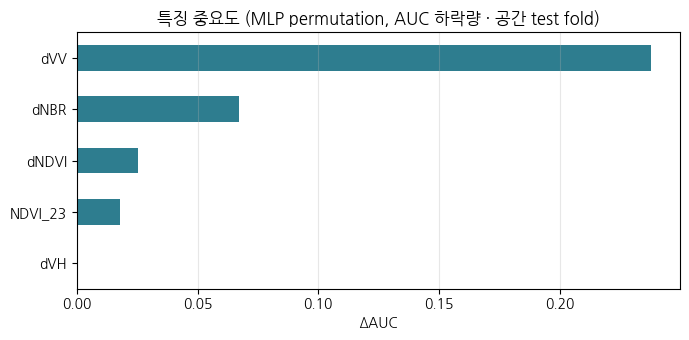

dVH        0.0003
NDVI_23    0.0178
dNDVI      0.0255
dNBR       0.0671
dVV        0.2379


In [10]:
rng = np.random.default_rng(42)
base_auc = roc_auc_score(y[te], predict(mlp, Xte))
imp = {}
for j, f in enumerate(FEATS):
    drops = []
    for _ in range(5):
        Xp = Xte.copy(); Xp[:, j] = rng.permutation(Xp[:, j])
        drops.append(base_auc - roc_auc_score(y[te], predict(mlp, Xp)))
    imp[f] = np.mean(drops)
imp = pd.Series(imp).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.5))
imp.plot.barh(ax=ax, color="#2e7d8f")
ax.set_title("특징 중요도 (MLP permutation, AUC 하락량 · 공간 test fold)")
ax.set_xlabel("ΔAUC"); ax.grid(alpha=0.3, axis="x")
plt.tight_layout(); plt.savefig("lava_state_v2_importance.png", dpi=150, bbox_inches="tight"); plt.show()
print(imp.round(4).to_string())

## 5) 라벨 임계값 민감도 — 연속 스윕

v1은 3.0/3.5/4.0 세 점만 봐서 두 점이 같은 값이었다(정보 없음). 잔열 임계를 2.0~5.5°C로 훑어
면적이 임계에 얼마나 민감한지 곡선으로 확인한다.

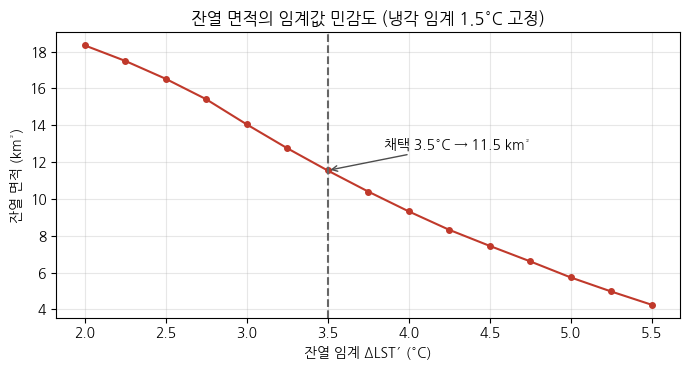

임계 ±0.5°C에서 잔열 면적 9.3~14.1 km² (채택 11.5) → 결론(잔열≫냉각)은 임계에 견고


In [11]:
thr_grid = np.arange(2.0, 5.6, 0.25)
hot_area = [A(_m & (dLSTa >= t)) for t in thr_grid]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(thr_grid, hot_area, "-o", ms=4, color="#c0392b")
ax.axvline(HOT_THR, ls="--", color="0.4")
ax.annotate(f"채택 {HOT_THR}°C → {area['잔열']:.1f} km²", (HOT_THR, area['잔열']),
            xytext=(HOT_THR+0.35, area['잔열']+1.2), fontsize=10,
            arrowprops=dict(arrowstyle="->", color="0.3"))
ax.set_xlabel("잔열 임계 ΔLST′ (°C)"); ax.set_ylabel("잔열 면적 (km²)")
ax.set_title("잔열 면적의 임계값 민감도 (냉각 임계 1.5°C 고정)")
ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("lava_state_v2_sensitivity.png", dpi=150, bbox_inches="tight"); plt.show()
s_lo, s_hi = A(_m & (dLSTa >= 3.0)), A(_m & (dLSTa >= 4.0))
print(f"임계 ±0.5°C에서 잔열 면적 {s_hi:.1f}~{s_lo:.1f} km² (채택 {area['잔열']:.1f}) → 결론(잔열≫냉각)은 임계에 견고")

## 6) 평가 종합 figure + 전체 분류 지도

- 평가: out-of-fold(공간 CV) 풀링 혼동행렬·ROC + 검증방식 비교 + 모델 비교
- 지도: 전체 라벨 가능 픽셀로 최종 모델을 학습(15% 검증 분리) → **합의 용암 21 km² 전체**에 적용.
  SAR 결측(커버 95%) 픽셀은 회색으로 정직하게 표기.

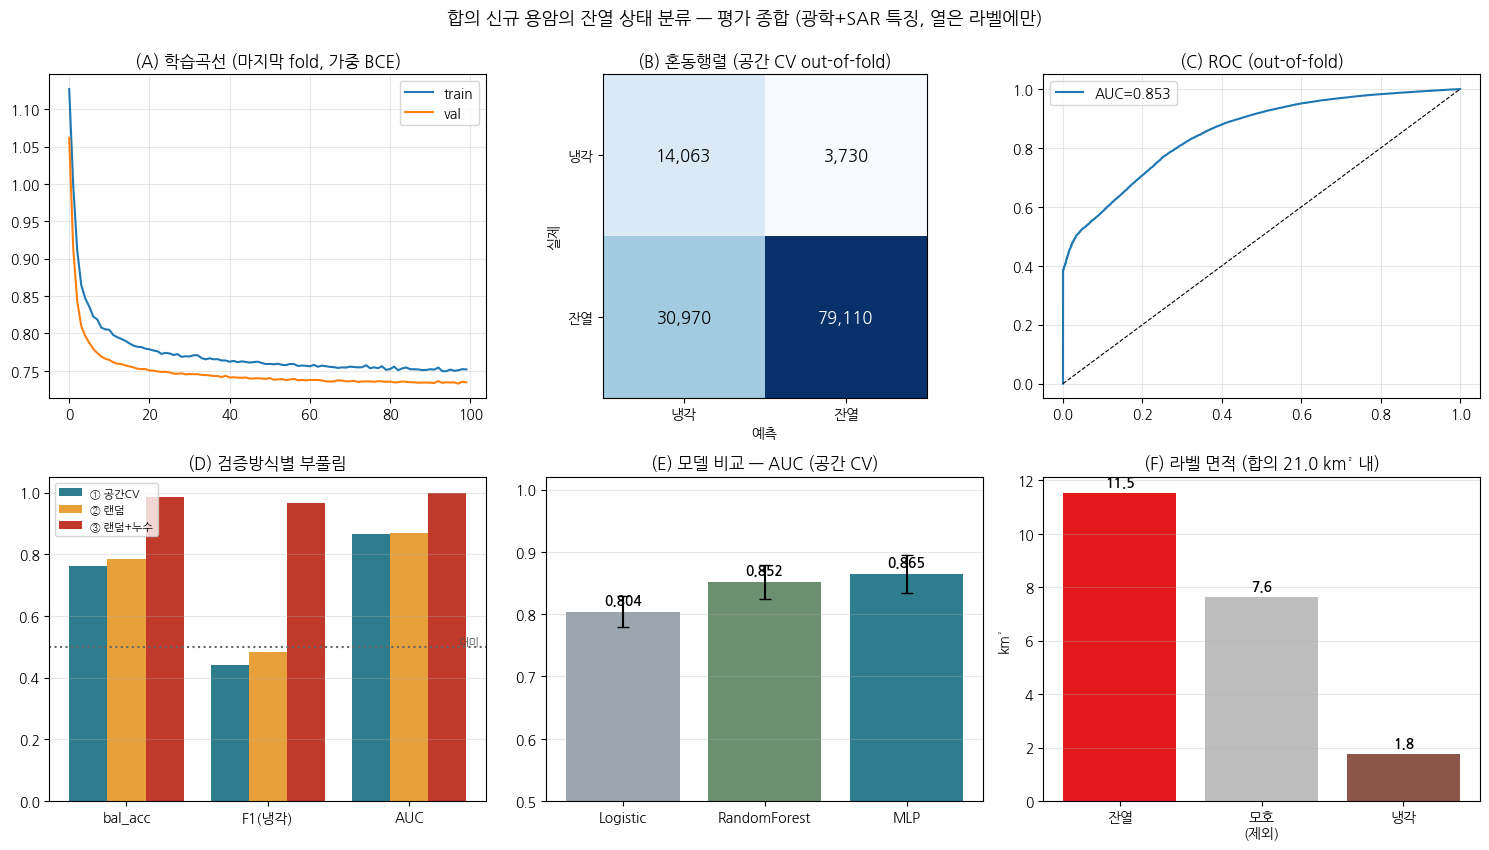

In [12]:
from sklearn.metrics import roc_curve, auc as auc_fn
pred_oof = (oof > 0.5).astype(int)
cm = confusion_matrix(y, pred_oof); fpr, tpr, _ = roc_curve(y, oof)

fig = plt.figure(figsize=(15, 8.5))
ax = plt.subplot(2, 3, 1)
ax.plot(hist_last["loss"], label="train"); ax.plot(hist_last["val_loss"], label="val")
ax.set_title("(A) 학습곡선 (마지막 fold, 가중 BCE)"); ax.legend(); ax.grid(alpha=0.3)

ax = plt.subplot(2, 3, 2)
ax.imshow(cm, cmap="Blues"); ax.set_xticks([0,1]); ax.set_yticks([0,1])
ax.set_xticklabels(["냉각", "잔열"]); ax.set_yticklabels(["냉각", "잔열"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i,j]:,}", ha="center", va="center",
                color="white" if cm[i,j] > cm.max()*0.6 else "black", fontsize=12)
ax.set_xlabel("예측"); ax.set_ylabel("실제"); ax.set_title("(B) 혼동행렬 (공간 CV out-of-fold)")

ax = plt.subplot(2, 3, 3)
ax.plot(fpr, tpr, label=f"AUC={auc_fn(fpr, tpr):.3f}"); ax.plot([0,1],[0,1],"k--", lw=0.8)
ax.set_title("(C) ROC (out-of-fold)"); ax.legend(); ax.grid(alpha=0.3)

ax = plt.subplot(2, 3, 4)
hx = np.arange(3)
for s, (lab_, r) in enumerate(honest.iterrows()):
    ax.bar(hx + s*0.27, [r.bal_acc, r["f1_냉각"], r.auc], 0.27,
           label=["① 공간CV", "② 랜덤", "③ 랜덤+누수"][s], color=["#2e7d8f", "#e8a13a", "#c0392b"][s])
ax.set_xticks(hx + 0.27); ax.set_xticklabels(["bal_acc", "F1(냉각)", "AUC"])
ax.axhline(0.5, ls=":", color="0.4"); ax.text(2.62, 0.505, "더미", fontsize=8, color="0.3")
ax.set_ylim(0, 1.05); ax.legend(fontsize=8); ax.set_title("(D) 검증방식별 부풀림"); ax.grid(alpha=0.3, axis="y")

ax = plt.subplot(2, 3, 5)
mm = cv.groupby("model")[["auc"]].mean().reindex(["Logistic", "RandomForest", "MLP"])
sd = cv.groupby("model")[["auc"]].std().reindex(mm.index)
ax.bar(mm.index, mm.auc, yerr=sd.auc, capsize=4, color=["#9aa5ad", "#6b8f71", "#2e7d8f"])
for i, v in enumerate(mm.auc): ax.text(i, v+0.012, f"{v:.3f}", ha="center", fontweight="bold")
ax.set_ylim(0.5, 1.02); ax.set_title("(E) 모델 비교 — AUC (공간 CV)"); ax.grid(alpha=0.3, axis="y")

ax = plt.subplot(2, 3, 6)
bb = ax.bar(["잔열", "모호\n(제외)", "냉각"], [area["잔열"], area["모호"], area["냉각"]],
            color=["#e31a1c", "#bdbdbd", "#8c564b"])
for b, v in zip(bb, [area["잔열"], area["모호"], area["냉각"]]):
    ax.text(b.get_x()+b.get_width()/2, v+0.25, f"{v:.1f}", ha="center", fontweight="bold")
ax.set_ylabel("km²"); ax.set_title(f"(F) 라벨 면적 (합의 {A(CONSENSUS):.1f} km² 내)"); ax.grid(alpha=0.3, axis="y")

plt.suptitle("합의 신규 용암의 잔열 상태 분류 — 평가 종합 (광학+SAR 특징, 열은 라벨에만)", fontsize=13, y=0.995)
plt.tight_layout(); plt.savefig("lava_state_v2_eval.png", dpi=150, bbox_inches="tight"); plt.show()

In [13]:
# ---- 최종 모델(전체 라벨 데이터) → 합의 용암 전체 지도 ----
sc_f = StandardScaler().fit(X)
Xt2, Xv2, yt2, yv2 = train_test_split(sc_f.transform(X).astype("float32"), y,
                                      test_size=0.15, stratify=y, random_state=42)
final_mlp, _ = fit_mlp(Xt2, yt2, Xv2, yv2)

cys, cxs = np.where(CONSENSUS)
Fall = np.stack([NDVI23[cys, cxs], dNDVI[cys, cxs], dNBR[cys, cxs],
                 dVV[cys, cxs], dVH[cys, cxs]], 1)
ok = np.isfinite(Fall).all(1)
pred_map = np.full((H, W), np.nan, "float32")
pred_map[cys[ok], cxs[ok]] = (predict(final_mlp, sc_f.transform(Fall[ok]).astype("float32")) > 0.5)
pred_map[cys[~ok], cxs[~ok]] = 2                       # SAR 결측
a_hot, a_cold, a_gap = A(pred_map == 1), A(pred_map == 0), A(pred_map == 2)
print(f"[모델 예측, 합의 {A(CONSENSUS):.1f} km² 전체] 잔열 {a_hot:.1f} / 냉각 {a_cold:.1f} / SAR결측 {a_gap:.1f} km²")

[모델 예측, 합의 21.0 km² 전체] 잔열 12.3 / 냉각 7.8 / SAR결측 0.9 km²


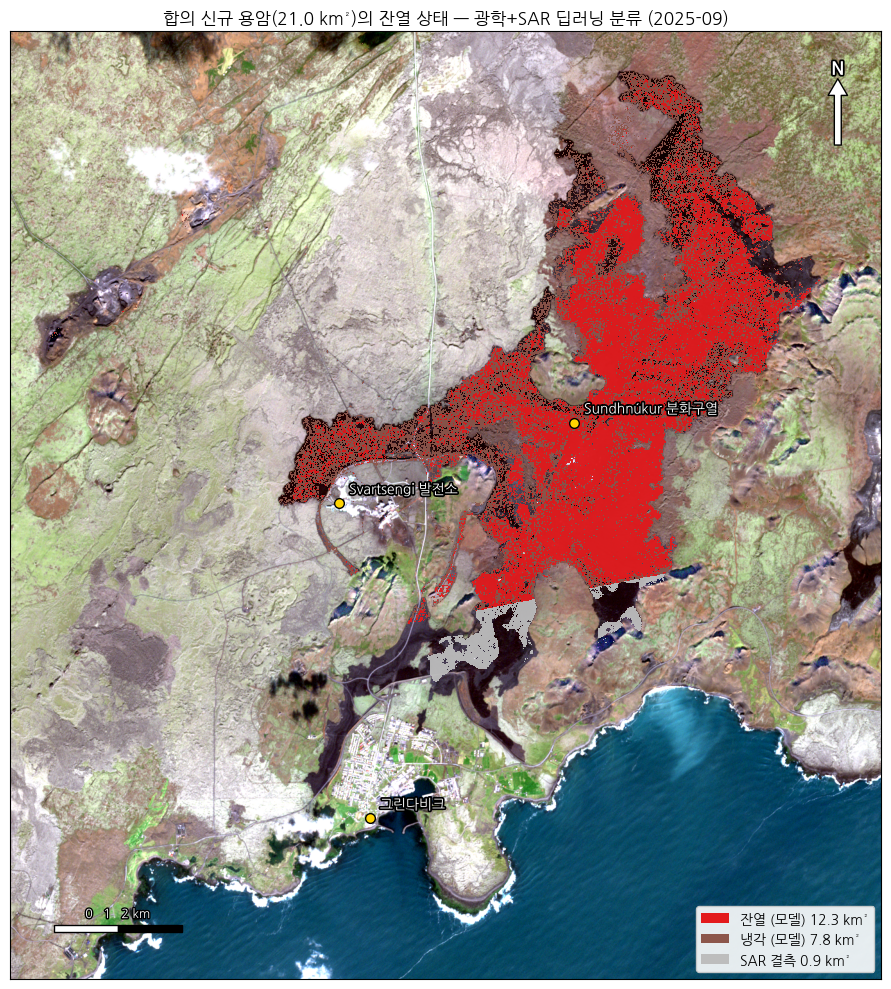

In [14]:
# ---- 분류 지도 (트루컬러 배경 + 간이 카토그래피) ----
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, Rectangle
import matplotlib.patheffects as pe
from pyproj import Transformer

def stretch(a, p=(2, 98)):
    lo, hi = np.nanpercentile(a, p)
    return np.clip((a-lo)/(hi-lo+1e-9), 0, 1)
rgb = np.nan_to_num(np.dstack([stretch(S2_25[b]) for b in (2, 1, 0)]) ** (1/1.25))

fig, ax = plt.subplots(figsize=(10.5, 10))
ax.imshow(rgb, extent=EXT, origin="upper")
cmap3 = ListedColormap(["#8c564b", "#e31a1c", "#bdbdbd"])     # 냉각/잔열/결측
ax.imshow(np.ma.masked_invalid(pred_map), extent=EXT, origin="upper",
          cmap=cmap3, vmin=0, vmax=2, interpolation="nearest", alpha=0.95)
_utm = Transformer.from_crs("EPSG:4326", CRS, always_xy=True)
for nm, la, lo in [("Sundhnúkur 분화구열", 63.892, -22.375), ("Svartsengi 발전소", 63.880, -22.449),
                   ("그린다비크", 63.836, -22.437)]:
    ux, uy = _utm.transform(lo, la)
    ax.plot(ux, uy, "o", ms=7, mfc="#ffd400", mec="black", zorder=6)
    ax.annotate(nm, (ux, uy), xytext=(7, 7), textcoords="offset points", fontsize=10,
                color="white", path_effects=[pe.withStroke(linewidth=2.5, foreground="black")])
# N 화살표 + 축척
ax.annotate("", xy=(0.95, 0.95), xytext=(0.95, 0.88), xycoords="axes fraction",
            arrowprops=dict(facecolor="white", edgecolor="black", width=5, headwidth=14))
ax.text(0.95, 0.955, "N", transform=ax.transAxes, ha="center", fontsize=13, fontweight="bold",
        color="white", path_effects=[pe.withStroke(linewidth=2.5, foreground="black")])
x0, y0 = EXT[0] + (EXT[1]-EXT[0])*0.05, EXT[2] + (EXT[3]-EXT[2])*0.05
for i, c in enumerate(["white", "black"]):
    ax.add_patch(Rectangle((x0 + i*1000, y0), 1000, 110, fc=c, ec="black", zorder=6))
ax.text(x0 + 1000, y0 + 220, "0   1   2 km", ha="center", fontsize=9, color="white",
        path_effects=[pe.withStroke(linewidth=2, foreground="black")], zorder=6)
ax.legend(handles=[Patch(fc="#e31a1c", label=f"잔열 (모델) {a_hot:.1f} km²"),
                   Patch(fc="#8c564b", label=f"냉각 (모델) {a_cold:.1f} km²"),
                   Patch(fc="#bdbdbd", label=f"SAR 결측 {a_gap:.1f} km²")],
          loc="lower right", fontsize=10, framealpha=0.9)
ax.set_title(f"합의 신규 용암({A(CONSENSUS):.1f} km²)의 잔열 상태 — 광학+SAR 딥러닝 분류 (2025-09)", fontsize=12.5)
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig("lava_state_v2_map.png", dpi=160, bbox_inches="tight"); plt.show()

## 7) 산출물 저장 + 최종 요약

In [15]:
if USE_CACHE:
    # 발표 figure 파이프라인(src/12_lava_state_figs.py)이 읽는 산출물
    prof = dict(driver="GTiff", height=H, width=W, count=1, dtype="float32",
                crs=CRS, transform=TRANSFORM, nodata=-9999, compress="deflate")
    with rasterio.open(f"{CACHE}/lava_state.tif", "w", **prof) as dst:
        dst.write(np.where(np.isfinite(pred_map), pred_map, -9999).astype("float32"), 1)
    js = dict(hot_thr=HOT_THR, cold_thr=COLD_THR,
              area_label=dict(hot=round(area["잔열"], 2), cold=round(area["냉각"], 2), ambig=round(area["모호"], 2)),
              area_pred=dict(hot=round(a_hot, 2), cold=round(a_cold, 2), gap=round(a_gap, 2)),
              consensus_km2=round(A(CONSENSUS), 2),
              cv_spatial={m: {k: round(float(v), 4) for k, v in g.items()}
                          for m, g in cv.groupby("model")[["bal_acc", "f1_잔열", "f1_냉각", "auc"]].mean().iterrows()},
              honesty={i: {k: round(float(v), 4) for k, v in r.items()} for i, r in honest.iterrows()},
              importance={k: round(float(v), 4) for k, v in imp.items()},
              n_pixels=int(len(df)), feats=FEATS)
    with open(f"{CACHE}/lava_state_stats.json", "w", encoding="utf-8") as f:
        json.dump(js, f, ensure_ascii=False, indent=1)
    print("저장: data/lava_state.tif, data/lava_state_stats.json")

mlp_row = honest.iloc[0]
print(f'''
{"="*72}
 최종 요약 — 잔열 상태 분류 (정직 보고)
{"="*72}
 합의 신규 용암      : {A(CONSENSUS):.2f} km²   (발표 공식 산출물과 동일)
 라벨(ΔLST′ 임계)    : 잔열 {area["잔열"]:.1f} / 냉각 {area["냉각"]:.1f} / 모호 제외 {area["모호"]:.1f} km²
 모델 예측(전체 적용): 잔열 {a_hot:.1f} / 냉각 {a_cold:.1f} / SAR결측 {a_gap:.1f} km²
 보고 지표(공간 CV)  : bal_acc {mlp_row.bal_acc:.3f} · F1(잔열) {mlp_row.f1_잔열:.3f} · F1(냉각) {mlp_row.f1_냉각:.3f} · AUC {mlp_row.auc:.3f}
 부풀림 진단         : 랜덤분할 AUC {honest.iloc[1].auc:.3f} / 랜덤+LST누수 AUC {honest.iloc[2].auc:.3f}
 해석: 광학+SAR만으로 잔열 구분이 {"가능" if mlp_row.auc >= 0.75 else "제한적"} (더미 AUC 0.5 대비)
{"="*72}''')

저장: data/lava_state.tif, data/lava_state_stats.json

 최종 요약 — 잔열 상태 분류 (정직 보고)
 합의 신규 용암      : 20.97 km²   (발표 공식 산출물과 동일)
 라벨(ΔLST′ 임계)    : 잔열 11.5 / 냉각 1.8 / 모호 제외 7.6 km²
 모델 예측(전체 적용): 잔열 12.3 / 냉각 7.8 / SAR결측 0.9 km²
 보고 지표(공간 CV)  : bal_acc 0.763 · F1(잔열) 0.820 · F1(냉각) 0.442 · AUC 0.865
 부풀림 진단         : 랜덤분할 AUC 0.870 / 랜덤+LST누수 AUC 0.999
 해석: 광학+SAR만으로 잔열 구분이 가능 (더미 AUC 0.5 대비)


## 참고 — 한계와 발표 연결

- **약지도 한계**: 현장 검증자료 없음. 라벨은 ΔLST′ 임계 기반 — "잔열"의 절대 온도가 아니라 배경 대비 상대 승온. 모호구간 제외로 라벨 잡음을 줄였고, LST 계열을 특징에서 제외해 누수를 차단함.
- **"흐르는 용암" 표현 금지**: 두 시점 모두 분화 휴지기. 진짜 활동 용암 탐지는 분화 에피소드 당일의 VIIRS/MODIS 열이상·S2 SWIR이 필요(발표 한계 슬라이드와 동일 논지).
- **발표 연결 제안**: 위험도(fig15, "언제 생겼나" — SWIR 구/신 분리)와 나란히 "**얼마나 식었나**(잔열)" 슬라이드로. 합의 21 km² 중 대부분이 아직 잔열을 보유한 것으로 분류됨 → 모니터링 우선순위 근거.
- **개선 방향**: VIIRS 열이상 시계열로 시점 라벨 정교화 → 잔열-경과시간 회귀, U-Net 픽셀 분할로 확장, InSAR 변형 추가.